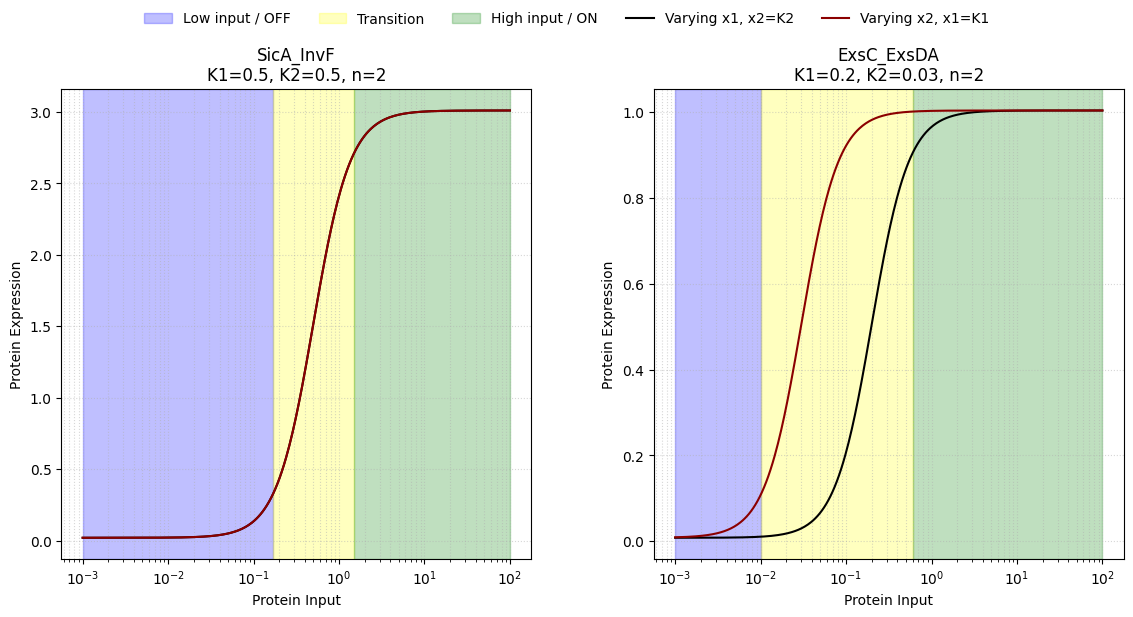

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Each row contains one AND gate and its parameters.
file = pd.read_csv("parsed_Eco3C3G3T3.csv")
file = file[file["type"] == "AND"].reset_index(drop=True)
if file.empty:
    raise ValueError("The CSV contains no AND gates to plot.")

fig, axes = plt.subplots(1, len(file), figsize=(6 * len(file), 6), squeeze=False)
x = np.logspace(-3, 2, 400)

for index, row in file.iterrows():
    axis = axes.flat[index]
    ymin, ymax = row["ymin"], row["ymax"]
    k1, k2, n = row["K1"], row["K2"], row["n"]

    # The bands approximate the transition range across both input thresholds.
    transition_factor = 9 ** (1 / n)
    transition_min = min(k1, k2) / transition_factor
    transition_max = max(k1, k2) * transition_factor
    axis.axvspan(
        x.min(), transition_min, color="blue", alpha=0.25,
        label="Low input / OFF" if index == 0 else None,
    )
    axis.axvspan(
        transition_min, transition_max, color="yellow", alpha=0.25,
        label="Transition" if index == 0 else None,
    )
    axis.axvspan(
        transition_max, x.max(), color="green", alpha=0.25,
        label="High input / ON" if index == 0 else None,
    )

    # Vary one input while holding the other at its half-response value.
    y_x1 = ymin + (ymax - ymin) * (x**n / (k1**n + x**n)) * 0.5
    y_x2 = ymin + (ymax - ymin) * 0.5 * (x**n / (k2**n + x**n))
    axis.plot(
        x, y_x1, color="black", linewidth=1.5,
        label="Varying x1, x2=K2", zorder=2,
    )
    axis.plot(
        x, y_x2, color="darkred", linewidth=1.5,
        label="Varying x2, x1=K1", zorder=2,
    )

    axis.set_xscale("log")
    axis.set_box_aspect(1)
    axis.set_title(f"{row['name']}\nK1={k1}, K2={k2}, n={n}")
    axis.set_xlabel("Protein Input")
    axis.set_ylabel("Protein Expression")
    axis.grid(True, which="both", linestyle=":", alpha=0.5)

fig.legend(
    *axes.flat[0].get_legend_handles_labels(),
    loc="upper center", ncol=5, frameon=False,
)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()